# Cross-family zero-shot baselines for Federalist → simplified modern English

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes sentence-transformers evaluate sacrebleu sacremoses bert-score datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os, re, json, math, time, gc, random, shutil
from pathlib import Path
from collections import Counter

from google.colab import drive, userdata
drive.mount("/content/drive")

WORKDIR = Path("/content/drive/MyDrive/federalist_lora")
V3_DIR = WORKDIR / "v3"
OUT_DIR = WORKDIR / "baselines"
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert OUT_DIR.resolve() != V3_DIR.resolve()
EVAL_MODELS_DIR = V3_DIR / "eval_models"
clf_dir, alm_dir = EVAL_MODELS_DIR / "style_clf", EVAL_MODELS_DIR / "archaic_lm"
AUDIT_PATH = V3_DIR / "pairs_v3_audit.jsonl"

EXISTING = {
    "Qwen-7B zero-shot (teacher)": "outputs_Qwen_7B_zero_shot.json",
    "Qwen-3B zero-shot":           "outputs_Qwen_3B_zero_shot.json",
    "v3 adapter":                  "outputs_v3_adapter.json",
}
NEW_SYSTEMS = {
    "Llama-3.1-8B zero-shot": dict(repo="meta-llama/Llama-3.1-8B-Instruct", family="Llama",   size="large"),
    "Llama-3.2-3B zero-shot": dict(repo="meta-llama/Llama-3.2-3B-Instruct", family="Llama",   size="small"),
    "Falcon3-7B zero-shot":   dict(repo="tiiuae/Falcon3-7B-Instruct",       family="Falcon3", size="large"),
    "Falcon3-3B zero-shot":   dict(repo="tiiuae/Falcon3-3B-Instruct",       family="Falcon3", size="small"),
}
SYSTEM_INFO = {"Qwen-7B zero-shot (teacher)": ("Qwen", "large"), "Qwen-3B zero-shot": ("Qwen", "small"),
               **{n: (s["family"], s["size"]) for n, s in NEW_SYSTEMS.items()}}
ORDER = ["Qwen-7B zero-shot (teacher)", "Qwen-3B zero-shot", *NEW_SYSTEMS, "v3 adapter"]

SEED = 42
EVAL_TEMPERATURE = 0.3
MAX_NEW_TOKENS = 450
BATCH = 8
DELETE_CACHE_AFTER = True

CLF_MAX_LEN = 384
ARCHAIC_LM_BASE = MODERN_LM = "gpt2"
EVAL_EMBEDDER = "sentence-transformers/all-mpnet-base-v2"
BERTSCORE_MODEL = "roberta-large"
N_BOOT = 2000

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret found: open models will work, gated ones (Llama) will be blocked.")

Mounted at /content/drive


In [ ]:
import evaluate
_sari = evaluate.load("sari")
print("SARI loads.")

needed = [AUDIT_PATH, clf_dir / "config.json", alm_dir / "config.json", *[V3_DIR / f for f in EXISTING.values()]]
missing = [p for p in needed if not p.exists()]
assert not missing, f"missing v3 files (run the v3 notebook first): {missing}"
print("v3 files found:", len(needed))

from huggingface_hub import hf_hub_download
RUN_SYSTEMS, BLOCKED = [], {}
for name, spec in NEW_SYSTEMS.items():
    try:
        hf_hub_download(spec["repo"], "config.json"); RUN_SYSTEMS.append(name); print(f"  access ok:       {spec['repo']}")
    except Exception as e:
        BLOCKED[name] = f"{type(e).__name__}: {str(e)[:140]}"; print(f"  ACCESS BLOCKED:  {spec['repo']}  ({type(e).__name__})")
if BLOCKED:
    print("\nBlocked systems will be skipped. To fix a gated model: open https://huggingface.co/<repo>, accept the license while logged in,")
    print("make sure the HF_TOKEN secret in Colab (key icon) has read access and 'Notebook access' switched on, then rerun this cell.")

SARI loads.
v3 files found: 6


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

  access ok:       meta-llama/Llama-3.1-8B-Instruct


config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

  access ok:       meta-llama/Llama-3.2-3B-Instruct


config.json:   0%|          | 0.00/652 [00:00<?, ?B/s]

  access ok:       tiiuae/Falcon3-7B-Instruct


config.json:   0%|          | 0.00/658 [00:00<?, ?B/s]

  access ok:       tiiuae/Falcon3-3B-Instruct


## 1. Load the held-out test chunks and the outputs already generated in v3

In [ ]:
audit = {}
for line in AUDIT_PATH.read_text(encoding="utf-8").splitlines():
    d = json.loads(line); audit[d["id"]] = d

blob = json.loads((V3_DIR / EXISTING["v3 adapter"]).read_text(encoding="utf-8"))
ids = blob["ids"]                                           # the exact chunks and order that v3 evaluated
assert all(audit[i]["split"] == "test" and audit[i]["kind"] == "long" and audit[i]["modern"] for i in ids), "unexpected test ids"
srcs = [audit[i]["original"] for i in ids]                   # raw Federalist input
refs = [audit[i]["modern"] for i in ids]                     # cached reference paraphrase
print(f"{len(ids)} test chunks from papers {sorted({int(i[3:5]) for i in ids})}; mean source length {sum(len(s.split()) for s in srcs) / len(srcs):.0f} words")

existing_out = {}
for name, f in EXISTING.items():
    d = json.loads((V3_DIR / f).read_text(encoding="utf-8"))
    assert d["ids"] == ids, f"{f}: chunk ids differ from the v3 adapter's, cannot compare"
    existing_out[name] = d["outputs"]
print("loaded existing outputs:", {k: len(v) for k, v in existing_out.items()})

69 test chunks from papers [31, 40, 50, 59, 63]; mean source length 155 words
loaded existing outputs: {'Qwen-7B zero-shot (teacher)': 69, 'Qwen-3B zero-shot': 69, 'v3 adapter': 69}


## 2. Generate zero-shot outputs for the new families
Each model is loaded in 4-bit, given the **same** prompt and raw Federalist text the Qwen zero-shot systems got, run on every test chunk, and freed. The first formatted prompt of each model is printed so you can check its chat template looks sane. Outputs are cached in `baselines/`, so a crash or restart does not repeat finished models.

In [ ]:
import numpy as np, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig
from huggingface_hub import scan_cache_dir

RULES = ("You rewrite 18th-century political prose into modern American English. Rules: "
         "(1) preserve every claim, example, qualification, and logical connective, and do not add anything that is not in the text; "
         "(2) keep all proper names (people, places, institutions, nations) exactly as written; "
         "(3) {style} "
         "(4) do not add commentary or summarize; "
         "(5) output only the rewritten text as a single paragraph.")
STYLE_TEXT = {
    "plain": "use short, direct sentences and everyday vocabulary, no archaic words, no rhetorical flourishes;",
}

ZS_SYSTEM = RULES.format(style=STYLE_TEXT["plain"])
print("ZERO-SHOT SYSTEM PROMPT:\n" + ZS_SYSTEM + "\n")

norm = lambda o: re.sub(r"\s*\n+\s*", " ", o).strip()

def build_prompt(tk, system, user):
    try:
        return tk.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": user}],
                                      tokenize=False, add_generation_prompt=True)
    except Exception:
        return tk.apply_chat_template([{"role": "user", "content": system + "\n\n" + user}], tokenize=False, add_generation_prompt=True)

def load_model(repo):
    tk = AutoTokenizer.from_pretrained(repo, padding_side="left")
    if tk.pad_token is None: tk.pad_token = tk.eos_token
    dt = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    lm = AutoModelForCausalLM.from_pretrained(
        repo, device_map={"": 0}, torch_dtype=dt,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=dt))
    return lm.eval(), tk

@torch.no_grad()
def chat_generate(lm, tk, system, users, bs=8, temperature=EVAL_TEMPERATURE, max_new_tokens=MAX_NEW_TOKENS):
    prompts = [build_prompt(tk, system, u) for u in users]
    order = sorted(range(len(users)), key=lambda i: len(prompts[i]))
    outs, ntok = [None] * len(users), [None] * len(users)
    def run(idx):
        enc = tk([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(lm.device)
        out = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature, top_p=0.9,
                          repetition_penalty=1.05, pad_token_id=tk.pad_token_id)
        L = enc["input_ids"].shape[1]
        for j, i in enumerate(idx):
            gen = out[j][L:]
            ntok[i] = int((gen != tk.pad_token_id).sum())
            outs[i] = norm(tk.decode(gen, skip_special_tokens=True))
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        try:
            run(idx)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            for i in idx: run([i])
    return outs, ntok

def purge_cache(repo):
    try:
        info = scan_cache_dir()
        revs = [r.commit_hash for ri in info.repos if ri.repo_id == repo for r in ri.revisions]
        if revs: info.delete_revisions(*revs).execute()
    except Exception as e:
        print("  (cache purge skipped:", type(e).__name__, ")")

def out_path(name): return OUT_DIR / ("outputs_" + re.sub(r"\W+", "_", name) + ".json")

ZERO-SHOT SYSTEM PROMPT:
You rewrite 18th-century political prose into modern American English. Rules: (1) preserve every claim, example, qualification, and logical connective, and do not add anything that is not in the text; (2) keep all proper names (people, places, institutions, nations) exactly as written; (3) use short, direct sentences and everyday vocabulary, no archaic words, no rhetorical flourishes; (4) do not add commentary or summarize; (5) output only the rewritten text as a single paragraph.



In [ ]:
FAILED = {}
for name, spec in NEW_SYSTEMS.items():
    path = out_path(name)
    if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("ids") == ids:
        print(f"{name}: cached, skipping"); continue
    if name not in RUN_SYSTEMS:
        print(f"{name}: skipped (no access; see preflight)"); continue
    lm = tk = None
    try:
        t0 = time.time(); print(f"\n=== {name}  [{spec['repo']}] ===")
        lm, tk = load_model(spec["repo"]); print(f"  loaded in {(time.time() - t0) / 60:.1f} min")
        print("  first prompt as the model sees it:\n  " + build_prompt(tk, ZS_SYSTEM, srcs[0])[:420].replace("\n", "\n  ") + " ...\n")
        torch.manual_seed(SEED); t1 = time.time()
        outs, ntok = chat_generate(lm, tk, ZS_SYSTEM, srcs, bs=BATCH)
        path.write_text(json.dumps({"ids": ids, "repo": spec["repo"], "outputs": outs, "new_tokens": ntok}), encoding="utf-8")
        print(f"  generated {len(outs)} outputs in {(time.time() - t1) / 60:.1f} min; example:\n  {outs[0][:300]}")
    except Exception as e:
        FAILED[name] = f"{type(e).__name__}: {str(e)[:300]}"; print(f"  FAILED: {FAILED[name]}")
    finally:
        lm = tk = None; gc.collect(); torch.cuda.empty_cache()
        if DELETE_CACHE_AFTER: purge_cache(spec["repo"])
print("\nfailed:", FAILED or "none", "| blocked:", list(BLOCKED) or "none")


=== Llama-3.1-8B zero-shot  [meta-llama/Llama-3.1-8B-Instruct] ===


tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

... (30 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

  loaded in 0.6 min
  first prompt as the model sees it:
  <|system|>
  You rewrite 18th-century political prose into modern American English. Rules: (1) preserve every claim, example, qualification, and logical connective, and do not add anything that is not in the text; (2) keep all proper names (people, places, institutions, nations) exactly as written; (3) use short, direct sentences and everyday vocabulary, no archaic words, no rhetorical flourishes; (4) do not add commen ...

  generated 69 outputs in 1.1 min; example:
  In various debates, there exist fundamental truths or initial premises that all further reasoning must hinge upon. These truths carry inherent credibility that precedes any contemplation or synthesis. When they fail to secure this endorsement, it could stem from either malfunctions or disturbances w

failed: none | blocked: none


## 3. Assemble all systems and check the raw outputs
A leading chat preamble is stripped from **every** system so none is penalised for chattiness. The table shows how many outputs were touched, how many were empty, and how many new-family outputs ran to the token limit (a sign the model did not stop on its own).

In [ ]:
_KW = r"(?:rewrit\w*|modern|text|version|simplif\w*|paraphras\w*|translat\w*|passage|result\w*|output)"
PREAMBLE = re.compile(r"^(?:(?:sure|certainly|of course|okay|ok)\b[,!. ]*)?(?:here(?:'s| is| are)\b[^:\n]{0,80}\b" + _KW + r"\b[^:\n]{0,60}:|the (?:rewritten|modern|simplified)\b[^:\n]{0,60}:|rewritten text:|modern english:)\s*", re.I)
strip_preamble = lambda t: PREAMBLE.sub("", t, count=1).strip()

new_out, new_ntok = {}, {}
for name in NEW_SYSTEMS:
    p = out_path(name)
    if p.exists():
        d = json.loads(p.read_text(encoding="utf-8"))
        if d["ids"] == ids: new_out[name] = d["outputs"]; new_ntok[name] = d.get("new_tokens")
raw = {**existing_out, **new_out}

outputs, rows = {}, []
for name in ORDER:
    if name not in raw: continue
    cleaned = [strip_preamble(t) for t in raw[name]]
    n_empty = sum(len(t.split()) == 0 for t in cleaned)
    cleaned = [t if t.split() else "." for t in cleaned]
    outputs[name] = cleaned
    nt = new_ntok.get(name)
    rows.append({"system": name, "family": SYSTEM_INFO.get(name, ("v3 (Qwen-3B + LoRA)", ""))[0],
                 "preamble stripped": sum(a != b for a, b in zip(raw[name], [strip_preamble(t) for t in raw[name]])),
                 "empty outputs": n_empty,
                 "hit token limit": "n/a (v3)" if nt is None else sum(x >= MAX_NEW_TOKENS for x in nt),
                 "mean words": round(float(np.mean([len(t.split()) for t in cleaned])), 1),
                 "median length ratio vs source": round(float(np.median([len(t.split()) / len(s.split()) for t, s in zip(cleaned, srcs)])), 2)})
import pandas as pd
from IPython.display import display
display(pd.DataFrame(rows).set_index("system"))
missing_sys = [n for n in NEW_SYSTEMS if n not in outputs]
if missing_sys: print("NOT AVAILABLE (blocked or failed):", missing_sys)
all_systems = {"source (Federalist)": srcs, "reference (cached paraphrase)": refs, **outputs}
print("\nsystems to score:", list(outputs))

,family,preamble stripped,empty outputs,hit token limit,mean words,median length ratio vs source
system,,,,,,
Qwen-7B zero-shot (teacher),Qwen,0,0,n/a (v3),119.3,0.77
Qwen-3B zero-shot,Qwen,0,0,n/a (v3),101.6,0.65
Llama-3.1-8B zero-shot,Llama,0,0,0,116.2,0.77
Llama-3.2-3B zero-shot,Llama,7,0,0,118.9,0.77
Falcon3-7B zero-shot,Falcon3,0,0,0,106.3,0.67
Falcon3-3B zero-shot,Falcon3,0,0,0,113.8,0.76
v3 adapter,v3 (Qwen-3B + LoRA),0,0,n/a (v3),113.4,0.74



systems to score: ['Qwen-7B zero-shot (teacher)', 'Qwen-3B zero-shot', 'Llama-3.1-8B zero-shot', 'Llama-3.2-3B zero-shot', 'Falcon3-7B zero-shot', 'Falcon3-3B zero-shot', 'v3 adapter']


## 4. Metrics

In [ ]:
from sacrebleu.metrics import BLEU
from bert_score import BERTScorer
from sentence_transformers import SentenceTransformer
import pandas as pd
from IPython.display import display

dev = "cuda"
assert ARCHAIC_LM_BASE == MODERN_LM, "the two perplexity models share one tokenizer, so they must be the same architecture/vocab"
ctk = AutoTokenizer.from_pretrained(str(clf_dir))
clf = AutoModelForSequenceClassification.from_pretrained(str(clf_dir)).to(dev).eval()
ltok = AutoTokenizer.from_pretrained(str(alm_dir))
alm = AutoModelForCausalLM.from_pretrained(str(alm_dir)).to(dev).eval()
mlm = AutoModelForCausalLM.from_pretrained(MODERN_LM).to(dev).eval()
eval_emb = SentenceTransformer(EVAL_EMBEDDER, device=dev); eval_emb.max_seq_length = 512
bscorer = BERTScorer(model_type=BERTSCORE_MODEL, lang="en", rescale_with_baseline=False, batch_size=16, device=dev)
_bleu = BLEU(effective_order=True)

@torch.no_grad()
def clf_prob(texts, bs=16):
    out = []
    for s in range(0, len(texts), bs):
        enc = ctk(texts[s:s + bs], return_tensors="pt", padding=True, truncation=True, max_length=CLF_MAX_LEN).to(dev)
        out += torch.softmax(clf(**enc).logits.float(), -1)[:, 1].cpu().tolist()
    return np.array(out)

@torch.no_grad()
def lm_nll(lm, texts, bs=8, max_len=1000):
    res = []
    for s in range(0, len(texts), bs):
        enc = [[ltok.bos_token_id] + ltok(t, add_special_tokens=False)["input_ids"][:max_len - 1] for t in texts[s:s + bs]]
        L = max(map(len, enc))
        ids_ = torch.tensor([e + [ltok.eos_token_id] * (L - len(e)) for e in enc]).to(dev)
        att = torch.tensor([[1] * len(e) + [0] * (L - len(e)) for e in enc]).to(dev)
        logits = lm(input_ids=ids_, attention_mask=att).logits[:, :-1].float()
        tgt, m = ids_[:, 1:], att[:, 1:].float()
        nll = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), reduction="none").view(tgt.shape)
        res += ((nll * m).sum(1) / m.sum(1)).cpu().tolist()
    return np.array(res)

def cos_pairs(a, b):
    ea = eval_emb.encode(a, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    eb = eval_emb.encode(b, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    return (ea * eb).sum(1).cpu().numpy()

def sari_items(src_, preds, refs_):
    return np.array([_sari.compute(sources=[s], predictions=[p], references=[[r]])["sari"] for s, p, r in zip(src_, preds, refs_)])

ARTIFACT = re.compile(r"\[[A-Z]+(?:_\d+)?\]|(?:^|\n|:\s*)[-•*]\s+\S")
nwords = lambda t: len(t.split())
NAN = np.full(len(ids), np.nan)

def score_system(name, texts):
    is_src, is_ref = name.startswith("source"), name.startswith("reference")
    M = {}
    pm = clf_prob(texts); M["clf_p_modern"] = pm; M["clf_is_modern"] = (pm > 0.5).astype(float)
    na, nm = lm_nll(alm, texts), lm_nll(mlm, texts)
    M["ppl_logratio"] = na - nm
    M["ppl_modern"] = np.exp(nm)
    M["bleu_src"] = NAN if is_src else np.array([_bleu.sentence_score(t, [s]).score for t, s in zip(texts, srcs)])
    M["bleu_ref"] = NAN if is_ref else np.array([_bleu.sentence_score(t, [r]).score for t, r in zip(texts, refs)])
    M["bertscore_src"] = NAN if is_src else bscorer.score(texts, srcs)[2].numpy()
    M["bertscore_ref"] = NAN if is_ref else bscorer.score(texts, refs)[2].numpy()
    M["cos_src"] = NAN if is_src else cos_pairs(texts, srcs)
    M["cos_ref"] = NAN if is_ref else cos_pairs(texts, refs)
    M["sari"] = NAN if is_ref else sari_items(srcs, texts, refs)
    M["len_ratio_src"] = NAN if is_src else np.array([nwords(t) / max(1, nwords(s)) for t, s in zip(texts, srcs)])
    M["len_ratio_ref"] = NAN if is_ref else np.array([nwords(t) / max(1, nwords(r)) for t, r in zip(texts, refs)])
    M["artifact"] = np.array([float(bool(ARTIFACT.search(t))) for t in texts])
    return M

all_systems = {"source (Federalist)": srcs, "reference (cached paraphrase)": refs, **outputs}
PER = {}
for name, texts in all_systems.items():
    t0 = time.time(); PER[name] = score_system(name, texts); print(f"  scored {name} ({time.time() - t0:.0f}s)")

long_df = pd.DataFrame([{"system": s, "id": ids[i], **{k: float(v[i]) for k, v in M.items()}} for s, M in PER.items() for i in range(len(ids))])
long_df.to_csv(OUT_DIR / "per_chunk_metrics_baselines.csv", index=False)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

... (20 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  scored source (Federalist) (10s)
  scored reference (cached paraphrase) (4s)
  scored Qwen-7B zero-shot (teacher) (7s)
  scored Qwen-3B zero-shot (7s)
  scored Llama-3.1-8B zero-shot (8s)
  scored Llama-3.2-3B zero-shot (7s)
  scored Falcon3-7B zero-shot (7s)
  scored Falcon3-3B zero-shot (7s)
  scored v3 adapter (7s)


In [ ]:
def boot_ci(v, tf=None):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0: return None
    rng = np.random.default_rng(SEED)
    means = v[rng.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5]); m = v.mean()
    return (tf(m), tf(lo), tf(hi)) if tf else (m, lo, hi)

def fmt(v, tf=None, pct=False, nd=3):
    r = boot_ci(v, tf)
    if r is None: return "–"
    m, lo, hi = r
    if pct: return f"{100*m:.0f}%  [{100*lo:.0f}, {100*hi:.0f}]"
    return f"{m:.{nd}f}  [{lo:.{nd}f}, {hi:.{nd}f}]"

GROUPS = {
    "Style transfer strength (higher = more modern)": [("clf_is_modern", "classifier acc", dict(pct=True)),
                                                        ("clf_p_modern", "mean P(modern)", {}),
                                                        ("ppl_logratio", "PPL ratio arch/mod (geo-mean)", dict(tf=np.exp, nd=2))],
    "Content preservation (higher = better)": [("bleu_src", "self-BLEU (vs source)", dict(nd=1)), ("bleu_ref", "BLEU (vs ref)", dict(nd=1)),
                                                ("bertscore_src", "BERTScore F1 (vs source)", {}), ("bertscore_ref", "BERTScore F1 (vs ref)", {}),
                                                ("cos_src", "cosine (vs source)", {}), ("cos_ref", "cosine (vs ref)", {})],
    "Simplicity": [("sari", "SARI", dict(nd=1)), ("len_ratio_src", "length ratio out/source", dict(nd=2)), ("len_ratio_ref", "length ratio out/ref", dict(nd=2))],
    "Sanity": [("ppl_modern", "PPL under modern LM (lower = more fluent)", dict(nd=1)), ("artifact", "artifact rate", dict(pct=True))],
}
numeric_rows = []
for title, cols in GROUPS.items():
    tab = {name: {label: fmt(PER[name][k], **kw) for k, label, kw in cols} for name in PER}
    print("\n" + title); display(pd.DataFrame(tab).T)
for name, M in PER.items():
    for k, v in M.items():
        r = boot_ci(v)
        numeric_rows.append({"system": name, "metric": k, "mean": None if r is None else r[0], "ci_lo": None if r is None else r[1], "ci_hi": None if r is None else r[2]})
pd.DataFrame(numeric_rows).to_csv(OUT_DIR / "eval_table_baselines.csv", index=False)

src_acc = float(np.nanmean(PER["source (Federalist)"]["clf_is_modern"])); ref_acc = float(np.nanmean(PER["reference (cached paraphrase)"]["clf_is_modern"]))
print(f"\nCALIBRATION: classifier says {100*src_acc:.0f}% of Federalist sources and {100*ref_acc:.0f}% of reference paraphrases are 'modern'.")
if src_acc > 0.1 or ref_acc < 0.8:
    print("  -> The classifier is not cleanly separating the two calibration rows. It may be keying on topic or genre instead of style; treat its numbers with caution.")

PAIRED = [("clf_p_modern", "P(modern)"), ("ppl_logratio", "log PPL ratio"), ("bertscore_src", "BERTScore vs source"), ("bertscore_ref", "BERTScore vs ref"),
          ("cos_src", "cosine vs source"), ("cos_ref", "cosine vs ref"), ("bleu_ref", "BLEU vs ref"), ("sari", "SARI")]
print("\nPAIRED COMPARISON (v3 minus other; positive = v3 higher; CI over chunks)")
for other in [s for s in outputs if s != "v3 adapter"]:
    print(f"\n  v3 adapter vs {other}")
    for k, label in PAIRED:
        d = PER["v3 adapter"][k] - PER[other][k]
        m, lo, hi = boot_ci(d)
        sig = "  <- CI excludes 0" if (lo > 0 or hi < 0) else ""
        print(f"    {label:22s} diff {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]  v3 higher on {int((d > 0).sum())}/{len(d)} chunks{sig}")

worst = np.argsort(PER["v3 adapter"]["bertscore_src"])[:3]
for i in worst:
    print(f"\n--- chunk {ids[i]}: v3 BERTScore vs source {PER['v3 adapter']['bertscore_src'][i]:.3f}")
    print("SOURCE: ", srcs[i][:350]); print("REF:    ", refs[i][:350])
    for s in outputs: print(f"{s[:22]:22s}", outputs[s][i][:350])


Style transfer strength (higher = more modern)


,classifier acc,mean P(modern),PPL ratio arch/mod (geo-mean)
source (Federalist),"0% [0, 0]","0.000 [0.000, 0.000]","0.74 [0.72, 0.76]"
reference (cached paraphrase),"67% [55, 77]","0.673 [0.565, 0.775]","1.09 [1.04, 1.14]"
Qwen-7B zero-shot (teacher),"42% [30, 54]","0.419 [0.306, 0.535]","0.99 [0.95, 1.03]"
Qwen-3B zero-shot,"75% [65, 86]","0.754 [0.652, 0.855]","1.27 [1.19, 1.35]"
Llama-3.1-8B zero-shot,"90% [83, 97]","0.897 [0.823, 0.968]","1.24 [1.20, 1.28]"
Llama-3.2-3B zero-shot,"83% [72, 91]","0.820 [0.723, 0.907]","1.17 [1.13, 1.21]"
Falcon3-7B zero-shot,"87% [78, 94]","0.868 [0.785, 0.942]","1.24 [1.20, 1.28]"
Falcon3-3B zero-shot,"61% [49, 72]","0.613 [0.501, 0.723]","1.25 [1.20, 1.29]"
v3 adapter,"61% [48, 72]","0.614 [0.488, 0.729]","1.08 [1.03, 1.12]"



Content preservation (higher = better)


,self-BLEU (vs source),BLEU (vs ref),BERTScore F1 (vs source),BERTScore F1 (vs ref),cosine (vs source),cosine (vs ref)
source (Federalist),–,"18.5 [16.1, 21.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]"
reference (cached paraphrase),"17.5 [15.1, 20.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]",–
Qwen-7B zero-shot (teacher),"28.1 [23.6, 32.6]","51.5 [46.9, 55.8]","0.921 [0.914, 0.927]","0.952 [0.947, 0.957]","0.895 [0.880, 0.910]","0.933 [0.919, 0.946]"
Qwen-3B zero-shot,"14.6 [9.5, 20.5]","15.1 [13.3, 17.0]","0.889 [0.880, 0.898]","0.908 [0.903, 0.913]","0.737 [0.707, 0.765]","0.816 [0.792, 0.837]"
Llama-3.1-8B zero-shot,"10.7 [9.3, 12.3]","23.9 [21.7, 26.2]","0.895 [0.892, 0.899]","0.924 [0.921, 0.928]","0.782 [0.761, 0.803]","0.875 [0.859, 0.889]"
Llama-3.2-3B zero-shot,"14.3 [11.9, 16.8]","21.8 [19.5, 24.1]","0.899 [0.894, 0.904]","0.921 [0.917, 0.924]","0.811 [0.790, 0.831]","0.871 [0.856, 0.886]"
Falcon3-7B zero-shot,"9.4 [7.9, 11.0]","22.0 [19.6, 24.4]","0.892 [0.888, 0.896]","0.924 [0.920, 0.928]","0.791 [0.771, 0.812]","0.874 [0.857, 0.890]"
Falcon3-3B zero-shot,"10.7 [8.5, 14.0]","14.4 [12.6, 16.4]","0.895 [0.890, 0.900]","0.909 [0.905, 0.912]","0.850 [0.831, 0.867]","0.851 [0.828, 0.871]"
v3 adapter,"20.2 [16.4, 24.2]","30.5 [27.5, 33.3]","0.909 [0.903, 0.915]","0.930 [0.926, 0.934]","0.860 [0.835, 0.881]","0.886 [0.865, 0.905]"



Simplicity


,SARI,length ratio out/source,length ratio out/ref
source (Federalist),"44.7 [43.7, 45.9]",–,"1.41 [1.36, 1.46]"
reference (cached paraphrase),–,"0.73 [0.70, 0.75]",–
Qwen-7B zero-shot (teacher),"69.2 [66.3, 71.8]","0.78 [0.75, 0.80]","1.08 [1.04, 1.12]"
Qwen-3B zero-shot,"44.4 [42.7, 46.0]","0.66 [0.63, 0.70]","0.93 [0.87, 0.98]"
Llama-3.1-8B zero-shot,"51.3 [49.4, 52.9]","0.77 [0.74, 0.79]","1.07 [1.03, 1.12]"
Llama-3.2-3B zero-shot,"50.7 [49.0, 52.4]","0.79 [0.75, 0.83]","1.10 [1.05, 1.15]"
Falcon3-7B zero-shot,"50.2 [48.1, 52.3]","0.70 [0.67, 0.73]","0.97 [0.93, 1.01]"
Falcon3-3B zero-shot,"45.4 [43.7, 47.0]","0.74 [0.71, 0.77]","1.04 [0.99, 1.09]"
v3 adapter,"56.3 [54.5, 58.0]","0.74 [0.71, 0.77]","1.03 [0.99, 1.07]"



Sanity


,PPL under modern LM (lower = more fluent),artifact rate
source (Federalist),"35.0 [32.3, 38.0]","0% [0, 0]"
reference (cached paraphrase),"34.0 [31.2, 36.9]","0% [0, 0]"
Qwen-7B zero-shot (teacher),"35.6 [32.7, 38.7]","0% [0, 0]"
Qwen-3B zero-shot,"50.0 [44.5, 55.9]","0% [0, 0]"
Llama-3.1-8B zero-shot,"32.1 [29.5, 34.9]","0% [0, 0]"
Llama-3.2-3B zero-shot,"30.4 [28.1, 32.9]","0% [0, 0]"
Falcon3-7B zero-shot,"38.8 [35.8, 42.2]","0% [0, 0]"
Falcon3-3B zero-shot,"43.6 [39.7, 48.4]","0% [0, 0]"
v3 adapter,"36.2 [32.8, 40.1]","0% [0, 0]"



CALIBRATION: classifier says 0% of Federalist sources and 67% of reference paraphrases are 'modern'.
  -> The classifier is not cleanly separating the two calibration rows. It may be keying on topic or genre instead of style; treat its numbers with caution (see the note at the top).

PAIRED COMPARISON  (v3 minus other; positive = v3 higher; CI over chunks)

  v3 adapter vs Qwen-7B zero-shot (teacher)
    P(modern)              diff +0.195  [+0.077, +0.316]  v3 higher on 50/69 chunks  <- CI excludes 0
    log PPL ratio          diff +0.085  [+0.048, +0.121]  v3 higher on 50/69 chunks  <- CI excludes 0
    BERTScore vs source    diff -0.012  [-0.018, -0.006]  v3 higher on 21/69 chunks  <- CI excludes 0
    BERTScore vs ref       diff -0.022  [-0.027, -0.018]  v3 higher on 8/69 chunks  <- CI excludes 0
    cosine vs source       diff -0.035  [-0.058, -0.014]  v3 higher on 23/69 chunks  <- CI excludes 0
    cosine vs ref          diff -0.047  [-0.068, -0.029]  v3 higher on 17/69 chunks  <

### Readability, sentence-level NLI, and joint pass rate (the v3 follow-up cells)

In [ ]:
def split_sentences(t):
    return re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", t.strip())          # same splitter as the v3 notebook

In [ ]:
def count_syl(w):
    w = re.sub(r"[^a-z]", "", w.lower())
    if not w: return 0
    n = len(re.findall(r"[aeiouy]+", w))
    if w.endswith("e") and not w.endswith(("le", "ee")) and n > 1: n -= 1
    if w.endswith("ed") and not re.search(r"[td]ed$", w) and n > 1: n -= 1
    return max(1, n)

def readability(text):
    sents = [s for s in split_sentences(text) if s.strip()] or [text]
    words = re.findall(r"[A-Za-z']+", text)
    if not words: return (np.nan,) * 4
    syl = [count_syl(w) for w in words]
    wps, spw = len(words) / len(sents), sum(syl) / len(words)
    return (0.39 * wps + 11.8 * spw - 15.59,
            wps,
            spw,
            100 * float(np.mean([x >= 3 for x in syl])))

for name, texts in all_systems.items():
    R = np.array([readability(t) for t in texts])
    PER[name].update(fkgl=R[:, 0], sent_len=R[:, 1], syl_per_word=R[:, 2], complex_pct=R[:, 3])

tab = {n: {"FKGL grade": fmt(PER[n]["fkgl"], nd=1), "words/sentence": fmt(PER[n]["sent_len"], nd=1),
           "syllables/word": fmt(PER[n]["syl_per_word"], nd=2), "% complex words": fmt(PER[n]["complex_pct"], nd=1)} for n in PER}
print("Readability (lower = easier). FKGL uses a heuristic syllable counter, so compare rows, not absolute grades.")
display(pd.DataFrame(tab).T)

print("\nPAIRED: FKGL, v3 minus other (negative = v3 is easier)")
for other in [s for s in PER if s != "v3 adapter"]:
    d = PER["v3 adapter"]["fkgl"] - PER[other]["fkgl"]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {m:+.2f}  [{lo:+.2f}, {hi:+.2f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))
print("\nCaution: FKGL falls when sentences are chopped short, with no change in vocabulary. Read it next to '% complex words'.")

Readability (lower = easier). FKGL uses a heuristic syllable counter, so compare rows, not absolute grades.


,FKGL grade,words/sentence,syllables/word,% complex words
source (Federalist),"20.5 [18.8, 22.4]","42.6 [38.4, 47.5]","1.65 [1.63, 1.67]","19.4 [18.6, 20.1]"
reference (cached paraphrase),"13.3 [12.4, 14.2]","24.2 [22.2, 26.6]","1.64 [1.62, 1.67]","18.0 [17.0, 19.1]"
Qwen-7B zero-shot (teacher),"15.2 [13.9, 16.8]","28.7 [25.6, 32.4]","1.66 [1.64, 1.69]","18.9 [17.9, 20.0]"
Qwen-3B zero-shot,"11.1 [10.0, 12.3]","23.6 [21.0, 26.4]","1.48 [1.46, 1.51]","12.3 [11.2, 13.5]"
Llama-3.1-8B zero-shot,"14.1 [13.3, 15.1]","26.4 [24.4, 28.6]","1.64 [1.62, 1.67]","18.2 [17.3, 19.3]"
Llama-3.2-3B zero-shot,"16.6 [15.4, 17.9]","31.2 [28.3, 34.4]","1.70 [1.68, 1.73]","20.2 [19.1, 21.2]"
Falcon3-7B zero-shot,"13.0 [12.3, 13.9]","23.2 [21.7, 25.4]","1.66 [1.64, 1.68]","18.3 [17.2, 19.5]"
Falcon3-3B zero-shot,"16.4 [15.7, 17.2]","26.4 [24.6, 28.5]","1.84 [1.81, 1.87]","25.5 [24.5, 26.6]"
v3 adapter,"13.8 [12.7, 15.0]","25.0 [22.5, 28.1]","1.66 [1.64, 1.69]","18.6 [17.5, 19.7]"



PAIRED: FKGL, v3 minus other (negative = v3 is easier)
  vs source (Federalist)              -6.71  [-8.35, -5.29]   <- CI excludes 0
  vs reference (cached paraphrase)    +0.56  [-0.51, +1.62]
  vs Qwen-7B zero-shot (teacher)      -1.44  [-2.66, -0.60]   <- CI excludes 0
  vs Qwen-3B zero-shot                +2.69  [+1.28, +3.99]   <- CI excludes 0
  vs Llama-3.1-8B zero-shot           -0.28  [-1.40, +0.86]
  vs Llama-3.2-3B zero-shot           -2.82  [-4.28, -1.48]   <- CI excludes 0
  vs Falcon3-7B zero-shot             +0.77  [-0.19, +1.85]
  vs Falcon3-3B zero-shot             -2.62  [-3.48, -1.66]   <- CI excludes 0

Caution: FKGL falls when sentences are chopped short, with no change in vocabulary. Read it next to '% complex words'.


In [ ]:
NLI_NAME = "roberta-large-mnli"
ntok = AutoTokenizer.from_pretrained(NLI_NAME)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(dev).eval()
id2l = {int(k): v.lower() for k, v in nli.config.id2label.items()}
iE = next(k for k, v in id2l.items() if v.startswith("entail")); iC = next(k for k, v in id2l.items() if v.startswith("contra"))
print("NLI labels:", id2l)

@torch.no_grad()
def nli_probs(prem, hyp, bs=32):
    E, C = [], []
    for s in range(0, len(prem), bs):
        enc = ntok(prem[s:s + bs], hyp[s:s + bs], return_tensors="pt", padding=True, truncation="only_first", max_length=400).to(dev)
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.softmax(nli(**enc).logits.float(), -1)
        E += p[:, iE].cpu().tolist(); C += p[:, iC].cpu().tolist()
    return np.array(E), np.array(C)

def windows(sents): return sents + [sents[i] + " " + sents[i + 1] for i in range(len(sents) - 1)]

def best_support(prem_sents, hyp_sents):
    W = windows(prem_sents)
    pairs = [(w, h) for h in hyp_sents for w in W]
    E, C = nli_probs([p for p, _ in pairs], [h for _, h in pairs])
    E, C = E.reshape(len(hyp_sents), len(W)), C.reshape(len(hyp_sents), len(W))
    return E.max(1), C.max(1), E.argmax(1)

def nli_chunk(src_text, out_text):
    ss, oo = split_sentences(src_text), split_sentences(out_text)
    if not ss or not oo: return [np.nan] * 5, None
    Eo, Co, arg = best_support(ss, oo)
    Es, _, _ = best_support(oo, ss)
    contra = float(np.mean((Eo < 0.5) & (Co > 0.5)))
    return [float(Eo.mean()), float((Eo >= 0.5).mean()), float(Es.mean()), float((Es >= 0.5).mean()), contra], (oo, Eo, arg, windows(ss))

NLI_ROWS = ["reference (cached paraphrase)", *outputs]
detail = {}
for name in PER:
    if name not in NLI_ROWS:
        for k in ("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra"): PER[name][k] = np.full(len(ids), np.nan)
        continue
    t0 = time.time(); rows, detail[name] = [], []
    for i in range(len(ids)):
        r, d = nli_chunk(srcs[i], all_systems[name][i]); rows.append(r); detail[name].append(d)
    R = np.array(rows)
    for j, k in enumerate(("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra")): PER[name][k] = R[:, j]
    print(f"  NLI scored {name} ({(time.time() - t0) / 60:.1f} min)")
del nli; gc.collect(); torch.cuda.empty_cache()

tab = {n: {"faithfulness (mean best-entail)": fmt(PER[n]["nli_faith"]), "% output sentences supported": fmt(PER[n]["faith_frac"], pct=True),
           "coverage (mean best-entail)": fmt(PER[n]["nli_cover"]), "% source sentences covered": fmt(PER[n]["cover_frac"], pct=True),
           "% output sentences contradicted": fmt(PER[n]["nli_contra"], pct=True)} for n in NLI_ROWS}
display(pd.DataFrame(tab).T)

print("\nPAIRED (v3 minus other; positive = v3 higher; for 'contradicted' lower is better)")
for other in [s for s in NLI_ROWS if s != "v3 adapter"]:
    print(f"\n  v3 adapter vs {other}")
    for k, label in [("nli_faith", "faithfulness"), ("faith_frac", "% sentences supported"), ("nli_cover", "coverage"), ("cover_frac", "% source covered"), ("nli_contra", "% contradicted")]:
        d = PER["v3 adapter"][k] - PER[other][k]; m, lo, hi = boot_ci(d)
        print(f"    {label:24s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

cand = [(Eo[j], i, j) for i, d in enumerate(detail["v3 adapter"]) if d is not None for j, _ in enumerate(d[0]) for Eo in [d[1]]]
print("\nLEAST-SUPPORTED v3 OUTPUT SENTENCES (check these by hand for meaning errors):")
for e, i, j in sorted(cand)[:8]:
    oo, Eo, arg, W = detail["v3 adapter"][i]
    print(f"\n  chunk {ids[i]} | support {e:.2f}\n    OUTPUT: {oo[j][:260]}\n    BEST SOURCE WINDOW: {W[arg[j]][:300]}")

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.43GB            

... (2 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NLI labels: {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
  NLI scored reference (cached paraphrase) (0.3 min)
  NLI scored Qwen-7B zero-shot (teacher) (0.3 min)
  NLI scored Qwen-3B zero-shot (0.3 min)
  NLI scored Llama-3.1-8B zero-shot (0.3 min)
  NLI scored Llama-3.2-3B zero-shot (0.3 min)
  NLI scored Falcon3-7B zero-shot (0.3 min)
  NLI scored Falcon3-3B zero-shot (0.3 min)
  NLI scored v3 adapter (0.3 min)


,faithfulness (mean best-entail),% output sentences supported,coverage (mean best-entail),% source sentences covered,% output sentences contradicted
reference (cached paraphrase),"0.943 [0.926, 0.958]","97% [96, 99]","0.765 [0.716, 0.806]","81% [74, 86]","1% [0, 2]"
Qwen-7B zero-shot (teacher),"0.966 [0.955, 0.976]","99% [98, 100]","0.831 [0.789, 0.869]","86% [80, 91]","0% [0, 1]"
Qwen-3B zero-shot,"0.848 [0.808, 0.884]","87% [82, 91]","0.675 [0.619, 0.728]","69% [61, 75]","4% [2, 6]"
Llama-3.1-8B zero-shot,"0.920 [0.891, 0.943]","94% [90, 97]","0.801 [0.757, 0.840]","84% [78, 89]","3% [0, 7]"
Llama-3.2-3B zero-shot,"0.894 [0.863, 0.921]","92% [88, 95]","0.811 [0.772, 0.848]","86% [81, 91]","2% [1, 4]"
Falcon3-7B zero-shot,"0.924 [0.897, 0.948]","95% [92, 98]","0.791 [0.745, 0.831]","86% [80, 91]","1% [0, 3]"
Falcon3-3B zero-shot,"0.909 [0.878, 0.935]","94% [92, 97]","0.779 [0.738, 0.817]","82% [76, 87]","2% [1, 5]"
v3 adapter,"0.913 [0.884, 0.939]","93% [90, 96]","0.765 [0.715, 0.810]","79% [73, 85]","2% [1, 4]"



PAIRED (v3 minus other; positive = v3 higher; for 'contradicted' lower is better)

  v3 adapter vs reference (cached paraphrase)
    faithfulness             -0.030  [-0.062, -0.001]   <- CI excludes 0
    % sentences supported    -0.042  [-0.078, -0.008]   <- CI excludes 0
    coverage                 +0.000  [-0.059, +0.054]
    % source covered         -0.016  [-0.099, +0.062]
    % contradicted           +0.010  [-0.009, +0.031]

  v3 adapter vs Qwen-7B zero-shot (teacher)
    faithfulness             -0.054  [-0.084, -0.027]   <- CI excludes 0
    % sentences supported    -0.060  [-0.093, -0.028]   <- CI excludes 0
    coverage                 -0.066  [-0.129, -0.007]   <- CI excludes 0
    % source covered         -0.067  [-0.152, +0.014]
    % contradicted           +0.018  [+0.001, +0.040]   <- CI excludes 0

  v3 adapter vs Qwen-3B zero-shot
    faithfulness             +0.065  [+0.020, +0.111]   <- CI excludes 0
    % sentences supported    +0.062  [+0.011, +0.112]   <- CI e

In [ ]:
THR = dict(p_modern=0.5,
           faith_frac=0.75,
           cover_frac=0.75,
           fkgl_drop=2.0,
           ppl_mult=1.5)
ppl_cap = THR["ppl_mult"] * np.median(PER["reference (cached paraphrase)"]["ppl_modern"])
print(f"fluency cap: PPL under modern LM <= {ppl_cap:.1f}\n")

def criteria(name):
    M = PER[name]
    return {"modern": M["clf_p_modern"] > THR["p_modern"],
            "faithful": M["faith_frac"] >= THR["faith_frac"],
            "complete": M["cover_frac"] >= THR["cover_frac"],
            "simpler": (PER["source (Federalist)"]["fkgl"] - M["fkgl"]) >= THR["fkgl_drop"],
            "fluent": M["ppl_modern"] <= ppl_cap,
            "no artifacts": M["artifact"] == 0}

JOINT = {}
rows = {}
for name in NLI_ROWS:
    c = criteria(name); joint = np.all(np.stack(list(c.values())), axis=0).astype(float); JOINT[name] = joint; PER[name]["joint_pass"] = joint
    rows[name] = {**{k: fmt(v.astype(float), pct=True) for k, v in c.items()}, "ALL (joint pass)": fmt(joint, pct=True)}
print("Share of chunks passing each criterion, and all of them together:")
display(pd.DataFrame(rows).T)
print("The 'reference' row shows what is achievable with these thresholds. If even it scores low, a threshold is too strict.")

print("\nPAIRED: joint pass, v3 minus other")
for other in [s for s in NLI_ROWS if s != "v3 adapter"]:
    d = JOINT["v3 adapter"] - JOINT[other]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {100*m:+.0f} pts  [{100*lo:+.0f}, {100*hi:+.0f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

fluency cap: PPL under modern LM <= 48.1

Share of chunks passing each criterion, and all of them together:


,modern,faithful,complete,simpler,fluent,no artifacts,ALL (joint pass)
reference (cached paraphrase),"67% [55, 77]","99% [96, 100]","71% [59, 81]","81% [71, 90]","90% [83, 97]","100% [100, 100]","33% [22, 45]"
Qwen-7B zero-shot (teacher),"42% [30, 54]","100% [100, 100]","78% [68, 87]","70% [58, 80]","90% [83, 97]","100% [100, 100]","25% [14, 35]"
Qwen-3B zero-shot,"75% [65, 86]","81% [71, 90]","52% [41, 64]","88% [81, 96]","58% [46, 70]","100% [100, 100]","12% [4, 20]"
Llama-3.1-8B zero-shot,"90% [83, 97]","91% [84, 97]","72% [61, 83]","77% [67, 86]","93% [86, 99]","100% [100, 100]","46% [35, 58]"
Llama-3.2-3B zero-shot,"83% [72, 91]","81% [72, 90]","77% [67, 87]","59% [48, 71]","96% [90, 100]","100% [100, 100]","32% [22, 43]"
Falcon3-7B zero-shot,"87% [78, 94]","94% [88, 99]","80% [70, 88]","86% [77, 93]","84% [75, 91]","100% [100, 100]","45% [33, 57]"
Falcon3-3B zero-shot,"61% [49, 72]","93% [86, 99]","71% [59, 81]","57% [45, 68]","68% [58, 80]","100% [100, 100]","16% [9, 25]"
v3 adapter,"61% [48, 72]","93% [87, 99]","68% [57, 78]","84% [75, 93]","84% [75, 93]","100% [100, 100]","28% [17, 39]"


The 'reference' row shows what is achievable with these thresholds. If even it scores low, a threshold is too strict.

PAIRED: joint pass, v3 minus other
  vs reference (cached paraphrase)    -6 pts  [-20, +9]
  vs Qwen-7B zero-shot (teacher)      +3 pts  [-9, +14]
  vs Qwen-3B zero-shot                +16 pts  [+3, +29]   <- CI excludes 0
  vs Llama-3.1-8B zero-shot           -19 pts  [-33, -4]   <- CI excludes 0
  vs Llama-3.2-3B zero-shot           -4 pts  [-19, +10]
  vs Falcon3-7B zero-shot             -17 pts  [-29, -6]   <- CI excludes 0
  vs Falcon3-3B zero-shot             +12 pts  [+0, +23]


## 5. Cross-family analysis
Three views of the same per-chunk scores: a headline table (means), paired comparisons that answer the two questions this notebook exists for (do other families behave like Qwen at the same size? how much does size matter within each family?), and a plot of faithfulness against simplification.

With 69 chunks from 5 papers and about 9 metrics per comparison, expect a few intervals to exclude 0 by chance. Look for patterns that repeat across several metrics, not single flagged lines.

HEADLINE (means over 69 test chunks; see the earlier cells for confidence intervals)


,classifier % modern,PPL ratio (geo-mean),self-BLEU,BERTScore vs src,cosine vs src,SARI,FKGL,% complex words,% sentences supported,% source covered,% contradicted,joint pass %,length ratio
source (Federalist),0,0.74,–,–,–,44.7,20.5,19.4,–,–,–,–,–
reference (cached paraphrase),67,1.09,17.5,0.905,0.843,–,13.3,18.0,97,81,1.3,33,0.73
Qwen-7B zero-shot (teacher),42,0.99,28.1,0.921,0.895,69.2,15.2,18.9,99,86,0.4,25,0.78
Qwen-3B zero-shot,75,1.27,14.6,0.889,0.737,44.4,11.1,12.3,87,69,3.8,12,0.66
Llama-3.1-8B zero-shot,90,1.24,10.7,0.895,0.782,51.3,14.1,18.2,94,84,3.0,46,0.77
Llama-3.2-3B zero-shot,83,1.17,14.3,0.899,0.811,50.7,16.6,20.2,92,86,2.5,32,0.79
Falcon3-7B zero-shot,87,1.24,9.4,0.892,0.791,50.2,13.0,18.3,95,86,1.2,45,0.70
Falcon3-3B zero-shot,61,1.25,10.7,0.895,0.850,45.4,16.4,25.5,94,82,2.5,16,0.74
v3 adapter,61,1.08,20.2,0.909,0.860,56.3,13.8,18.6,93,79,2.2,28,0.74



A. SAME SIZE, DIFFERENT FAMILY (is Qwen special?)

  Llama-3.1-8B zero-shot  minus  Qwen-7B zero-shot (teacher)
    P(modern)                +0.478  [+0.361, +0.590]   <- CI excludes 0   (first is better)
    log PPL ratio            +0.223  [+0.185, +0.263]   <- CI excludes 0   (first is better)
    BERTScore vs src         -0.026  [-0.032, -0.019]   <- CI excludes 0   (second is better)
    cosine vs src            -0.113  [-0.135, -0.090]   <- CI excludes 0   (second is better)
    % sentences supported    -0.050  [-0.092, -0.015]   <- CI excludes 0   (second is better)
    % source covered         -0.020  [-0.090, +0.050]
    FKGL (lower = easier)    -1.154  [-2.667, +0.272]
    SARI                     -17.907  [-20.769, -14.915]   <- CI excludes 0   (second is better)
    joint pass               +0.217  [+0.072, +0.362]   <- CI excludes 0   (first is better)

  Falcon3-7B zero-shot  minus  Qwen-7B zero-shot (teacher)
    P(modern)                +0.449  [+0.330, +0.564]   <- CI

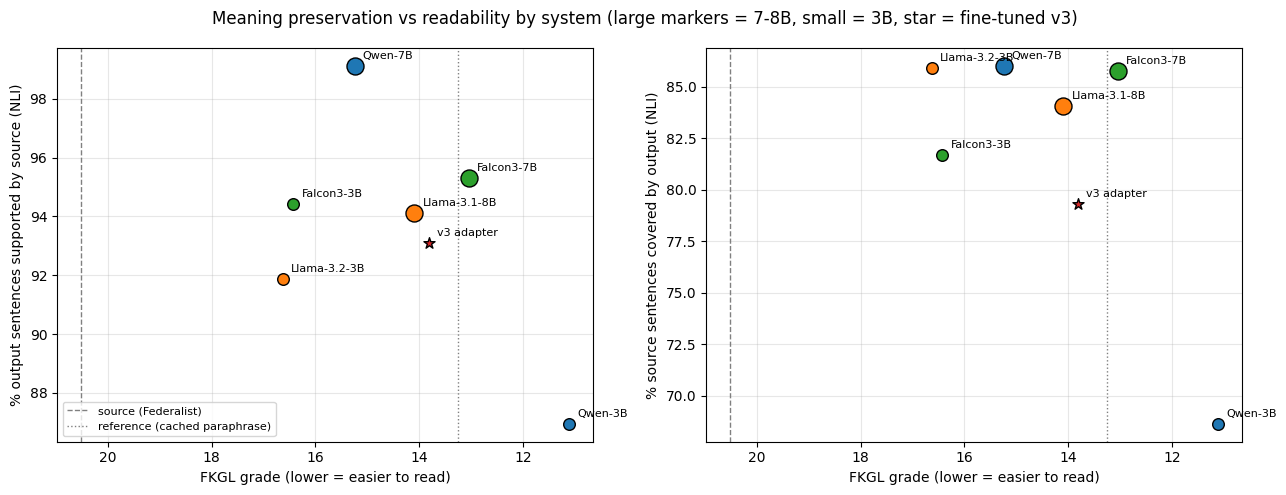

In [ ]:
def mean_or_dash(M, k, scale=1.0, nd=3):
    v = np.asarray(M[k], float); return "–" if np.isnan(v).all() else f"{np.nanmean(v) * scale:.{nd}f}"

HEAD = [("clf_is_modern", "classifier % modern", 100, 0), ("ppl_logratio", "PPL ratio (geo-mean)", None, 2),
        ("bleu_src", "self-BLEU", 1, 1), ("bertscore_src", "BERTScore vs src", 1, 3), ("cos_src", "cosine vs src", 1, 3),
        ("sari", "SARI", 1, 1), ("fkgl", "FKGL", 1, 1), ("complex_pct", "% complex words", 1, 1),
        ("faith_frac", "% sentences supported", 100, 0), ("cover_frac", "% source covered", 100, 0),
        ("nli_contra", "% contradicted", 100, 1), ("joint_pass", "joint pass %", 100, 0), ("len_ratio_src", "length ratio", 1, 2)]

order_rows = [s for s in ["source (Federalist)", "reference (cached paraphrase)", *ORDER] if s in PER]
tab = {}
for s in order_rows:
    r = {}
    for k, label, scale, nd in HEAD:
        if k not in PER[s]: r[label] = "–"
        elif k == "ppl_logratio": r[label] = "–" if np.isnan(PER[s][k]).all() else f"{np.exp(np.nanmean(PER[s][k])):.2f}"
        else: r[label] = mean_or_dash(PER[s], k, scale, nd)
    tab[s] = r
head_df = pd.DataFrame(tab).T
display(head_df)
head_df.to_csv(OUT_DIR / "headline_table_baselines.csv")

CMP = [("clf_p_modern", "P(modern)", +1), ("ppl_logratio", "log PPL ratio", +1), ("bertscore_src", "BERTScore vs src", +1), ("cos_src", "cosine vs src", +1),
       ("faith_frac", "% sentences supported", +1), ("cover_frac", "% source covered", +1), ("fkgl", "FKGL (lower = easier)", -1),
       ("sari", "SARI", +1), ("joint_pass", "joint pass", +1)]

def compare(a, b):
    if a not in PER or b not in PER: print(f"\n  {a} vs {b}: skipped (missing system)"); return
    print(f"\n  {a}  minus  {b}")
    for k, label, sign in CMP:
        d = np.asarray(PER[a][k], float) - np.asarray(PER[b][k], float)
        if np.isnan(d).all(): continue
        m, lo, hi = boot_ci(d); flag = "   <- CI excludes 0" if (lo > 0 or hi < 0) else ""
        verdict = "" if not flag else ("   (first is better)" if np.sign(m) == sign else "   (second is better)")
        print(f"    {label:24s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]{flag}{verdict}")

print("\n" + "=" * 90 + "\nA. SAME SIZE, DIFFERENT FAMILY\n" + "=" * 90)
for a, b in [("Llama-3.1-8B zero-shot", "Qwen-7B zero-shot (teacher)"), ("Falcon3-7B zero-shot", "Qwen-7B zero-shot (teacher)"),
             ("Llama-3.2-3B zero-shot", "Qwen-3B zero-shot"), ("Falcon3-3B zero-shot", "Qwen-3B zero-shot")]: compare(a, b)

print("\n" + "=" * 90 + "\nB. SIZE EFFECT WITHIN EACH FAMILY\n" + "=" * 90)
for a, b in [("Qwen-7B zero-shot (teacher)", "Qwen-3B zero-shot"), ("Llama-3.1-8B zero-shot", "Llama-3.2-3B zero-shot"),
             ("Falcon3-7B zero-shot", "Falcon3-3B zero-shot")]: compare(a, b)

print("\n" + "=" * 90 + "\nC. THE FINE-TUNED v3 ADAPTER vs EACH SMALL ZERO-SHOT MODEL\n" + "=" * 90)
for b in ["Qwen-3B zero-shot", "Llama-3.2-3B zero-shot", "Falcon3-3B zero-shot"]: compare("v3 adapter", b)

import matplotlib.pyplot as plt
COL = {"Qwen": "tab:blue", "Llama": "tab:orange", "Falcon3": "tab:green", "v3": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (k, ylabel) in zip(axes, [("faith_frac", "% output sentences supported by source (NLI)"), ("cover_frac", "% source sentences covered by output (NLI)")]):
    for s in ORDER:
        if s not in PER: continue
        fam, size = SYSTEM_INFO.get(s, ("v3", "small"))
        x, y = np.nanmean(PER[s]["fkgl"]), 100 * np.nanmean(PER[s][k])
        ax.scatter(x, y, s=150 if size == "large" else 70, color=COL[fam], marker="*" if fam == "v3" else "o", edgecolor="k", zorder=3)
        ax.annotate(s.replace(" zero-shot", "").replace(" (teacher)", ""), (x, y), textcoords="offset points", xytext=(6, 5), fontsize=8)
    for s, style in (("source (Federalist)", "--"), ("reference (cached paraphrase)", ":")):
        ax.axvline(np.nanmean(PER[s]["fkgl"]), color="gray", ls=style, lw=1, label=s)
    ax.set_xlabel("FKGL grade (lower = easier to read)"); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.invert_xaxis()
axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Meaning preservation vs readability by system")
plt.tight_layout(); plt.savefig(OUT_DIR / "faithfulness_vs_readability.png", dpi=150); plt.show()

## 6. Save the run summary

In [ ]:
import transformers
summary = {
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
    "new_systems": {n: {"repo": s["repo"], "family": s["family"], "size": s["size"], "ran": n in outputs} for n, s in NEW_SYSTEMS.items()},
    "failed": FAILED, "blocked": BLOCKED,
    "decoding": {"temperature": EVAL_TEMPERATURE, "top_p": 0.9, "repetition_penalty": 1.05, "max_new_tokens": MAX_NEW_TOKENS, "seed": SEED, "quantization": "4-bit nf4"},
    "zero_shot_system_prompt": ZS_SYSTEM,
    "preamble_stripped": {name: sum(a != b for a, b in zip(raw[name], outputs[name])) for name in outputs},
    "n_test_chunks": len(ids), "test_ids": ids,
    "headline_table": head_df.to_dict(orient="index"),
    "outputs": outputs,
}
(OUT_DIR / "run_summary_baselines.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("files in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()): print("  ", p.name)

files in /content/drive/MyDrive/federalist_lora/baselines
   eval_table_baselines.csv
   faithfulness_vs_readability.png
   headline_table_baselines.csv
   outputs_Falcon3_3B_zero_shot.json
   outputs_Falcon3_7B_zero_shot.json
   outputs_Llama_3_1_8B_zero_shot.json
   outputs_Llama_3_2_3B_zero_shot.json
   per_chunk_metrics_baselines.csv
   run_summary_baselines.json


## How to read the results
- **Is the Qwen result a Qwen result?** Compare section A. If Llama and Falcon3 at the same size land near Qwen on the source-based metrics (NLI support and coverage, BERTScore vs source, FKGL), the v3 conclusions generalise. If one family is clearly more faithful or simpler, the "teacher" choice matters more than the fine-tuning did.
- **Does size matter the same way everywhere?** Section B. A consistent drop in coverage and support from large to small across all three families would support "small models drop content" as a general finding, not a Qwen quirk.
- **Does fine-tuning beat prompting?** Section C. This compares the fine-tuned v3 adapter with three prompted 3B models. If v3 is ahead of all three on meaning preservation, the gain is from fine-tuning. If it is only ahead of Qwen-3B, the zero-shot Qwen-3B baseline was just weak.
- Remember the references come from your baseline paraphraser. Do not rank families on BLEU vs ref, BERTScore vs ref, or SARI alone.